# PRIM — When Does Pooling Reduce T1 Mortality?

For each of the 8 non-strict policies (3×3 grid minus baseline),
compares `death_rate_T1_BCAS` against the strict baseline (0,0)
and runs PRIM to discover the uncertainty sub-space where that
specific pooling policy **reduces** T1 mortality.

**Requires** a results.csv from an experiment with 3-level FF lever
variation over `facility_eligibility` and `ambulance_eligibility`.

In [1]:
import sys
from pathlib import Path
_root = Path(".").resolve()
while not (_root / "paths.py").exists():
    _root = _root.parent
sys.path.insert(0, str(_root))
import paths

In [2]:
FOLDER_NAME = "20260527_000623_scenario_elia_midterm"
LEVER_COLS  = ["facility_eligibility", "ambulance_eligibility"]
OUTCOME     = "death_rate_T1_BCAS"

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from ema_workbench.analysis import prim

run_folder = paths.MULTI_RUN_OUTPUT / FOLDER_NAME

df = pd.read_csv(run_folder / "results.csv")
print(f"Loaded {len(df)} runs  |  {df['scenario'].nunique()} scenarios  |  "
      f"{df['policy'].nunique()} distinct policies")
for lev in LEVER_COLS:
    print(f"  {lev}: {sorted(df[lev].unique())}")

C:\Users\User\Documents\thesis\medevac_model\.venv\Lib\site-packages\ema_workbench\em_framework\__init__.py:101: UserWarning: ipyparallel not installed - IpyparalleEvaluator not available
  warnings.warn("ipyparallel not installed - IpyparalleEvaluator not available")


Loaded 900 runs  |  100 scenarios  |  18 distinct policies
  facility_eligibility: [np.int64(0), np.int64(1), np.int64(2)]
  ambulance_eligibility: [np.int64(0), np.int64(1), np.int64(2)]


In [4]:
meta_cols      = ["scenario", "policy", "model"]
meta_start     = min(df.columns.get_loc(c) for c in meta_cols if c in df.columns)
input_cols     = df.columns[:meta_start].tolist()
uncertainty_cols = [c for c in input_cols if c not in LEVER_COLS]

print(f"Uncertainties ({len(uncertainty_cols)}): {uncertainty_cols}")
print(f"Levers ({len(LEVER_COLS)}): {LEVER_COLS}")

baseline_mask = (df["facility_eligibility"] == 0) & (df["ambulance_eligibility"] == 0)
baseline_outcome = (
    df.loc[baseline_mask]
    .groupby("scenario")[OUTCOME]
    .mean()
    .rename("strict")
)

x_all = (
    df.loc[baseline_mask]
    .drop_duplicates(subset="scenario")
    .set_index("scenario")
    [uncertainty_cols]
    .astype(float)
)

# All non-strict policies
POLICIES = [
    (fe, ae)
    for fe in sorted(df["facility_eligibility"].unique())
    for ae in sorted(df["ambulance_eligibility"].unique())
    if not (fe == 0 and ae == 0)
]
POLICY_LABELS = {0: "strict", 1: "bn_pool", 2: "bde_pool"}
print(f"\nNon-strict policies: {len(POLICIES)}")
for fe, ae in POLICIES:
    print(f"  fac={POLICY_LABELS[fe]}({fe}), amb={POLICY_LABELS[ae]}({ae})")

Uncertainties (14): ['axp_r1_other_bde_min', 'axp_r1_same_bde_min', 'bcas_rate', 'ccp_r1_inter_bn_min', 'ccp_r1_same_bn_min', 'fraction_t1_bcas', 'fraction_t2_bcas', 'r1_r1_inter_bn_min', 'r1_r2_other_bde_min', 'r1_r2_same_bde_min', 'r2_r2_other_bde_min', 'seed', 'wave_duration_min', 'waves_per_day']
Levers (2): ['facility_eligibility', 'ambulance_eligibility']

Non-strict policies: 8
  fac=strict(0), amb=bn_pool(1)
  fac=strict(0), amb=bde_pool(2)
  fac=bn_pool(1), amb=strict(0)
  fac=bn_pool(1), amb=bn_pool(1)
  fac=bn_pool(1), amb=bde_pool(2)
  fac=bde_pool(2), amb=strict(0)
  fac=bde_pool(2), amb=bn_pool(1)
  fac=bde_pool(2), amb=bde_pool(2)


## Per-Policy PRIM: Under Which Conditions Does This Policy Reduce T1 Mortality?

For each non-strict policy, computes `delta = strict - policy` for `death_rate_T1_BCAS`.
Positive delta = pooling reduced mortality (good). Runs PRIM on the binary
indicator `delta > 0`.


  fac=strict, amb=bn_pool  —  pooling reduces T1 mortality in 51/100 scenarios (51.0%)
  mean delta (strict − policy): 0.0077


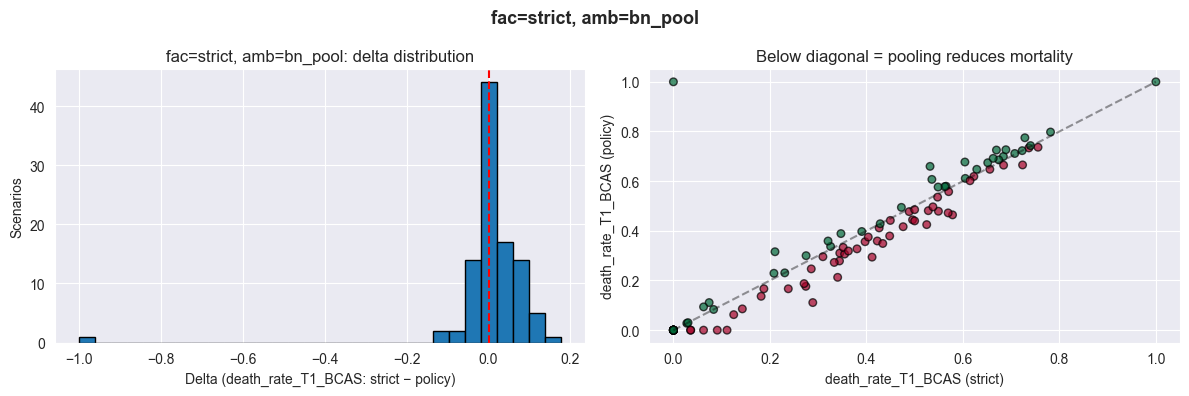

  Auto-selected box 26  (coverage=0.73, density=0.97)


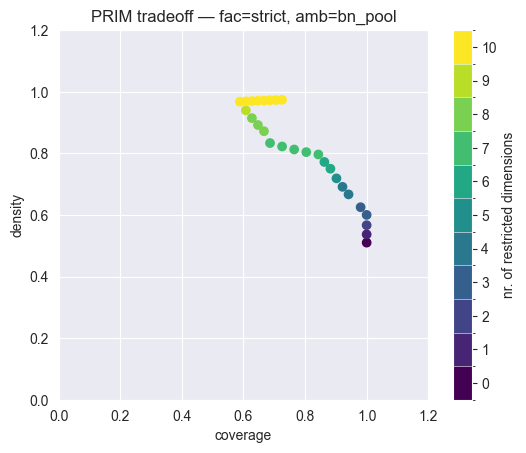

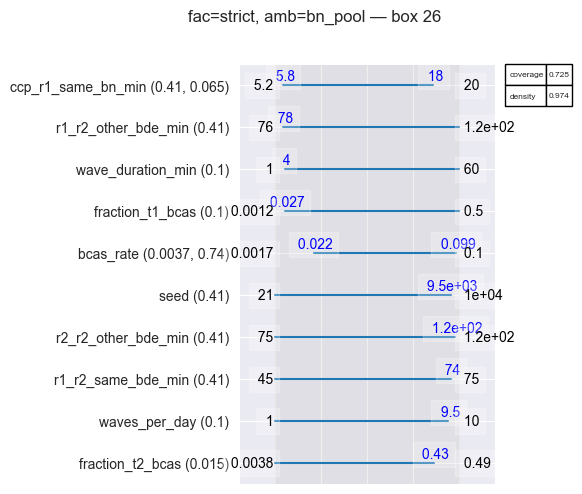

    bcas_rate                       [0.02, 0.10]  (full: [0.00, 0.10])
    ccp_r1_same_bn_min              [5.80, 17.93]  (full: [5.16, 19.96])
    fraction_t1_bcas                [0.03, 0.50]  (full: [0.00, 0.50])
    fraction_t2_bcas                [0.00, 0.43]  (full: [0.00, 0.49])
    r1_r2_other_bde_min             [77.63, 119.90]  (full: [75.68, 119.90])
    r1_r2_same_bde_min              [45.09, 73.62]  (full: [45.09, 74.91])
    r2_r2_other_bde_min             [75.02, 118.91]  (full: [75.02, 119.66])
    seed                            [21.00, 9534.00]  (full: [21.00, 9963.00])
    wave_duration_min               [4.00, 60.00]  (full: [1.00, 60.00])
    waves_per_day                   [1.00, 9.50]  (full: [1.00, 10.00])


  fac=strict, amb=bde_pool  —  pooling reduces T1 mortality in 26/100 scenarios (26.0%)
  mean delta (strict − policy): -0.0573


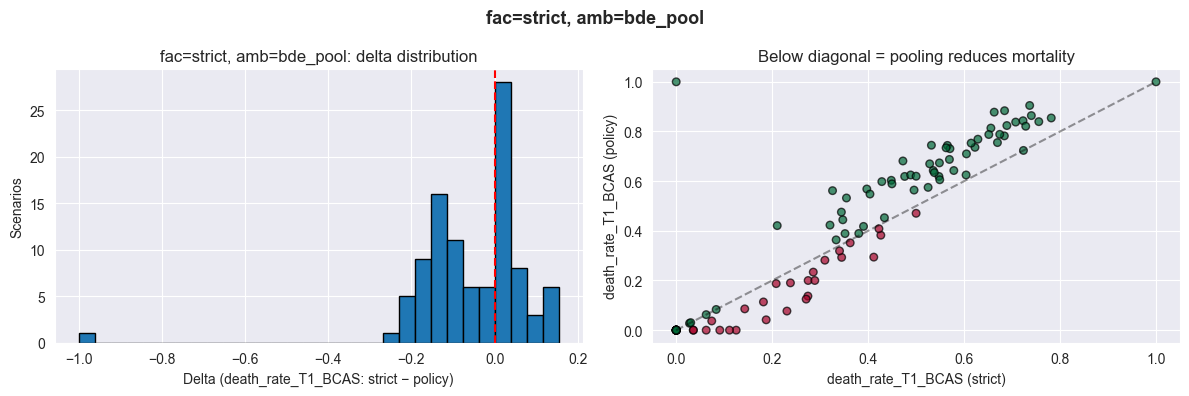

  Auto-selected box 27  (coverage=0.62, density=0.94)


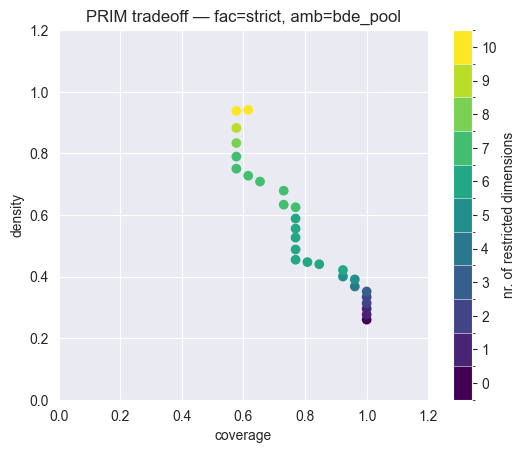

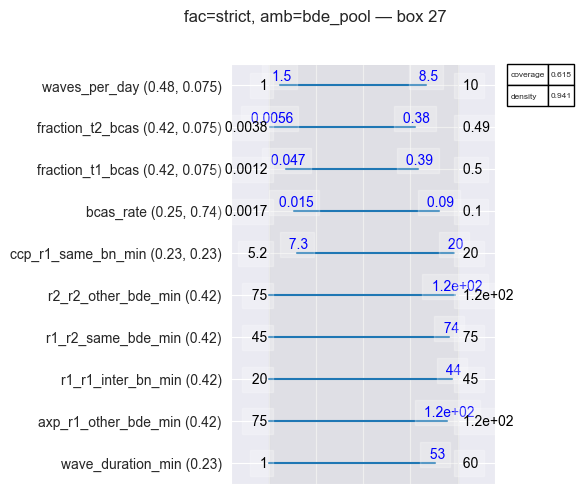

    axp_r1_other_bde_min            [75.20, 117.41]  (full: [75.20, 119.81])
    bcas_rate                       [0.01, 0.09]  (full: [0.00, 0.10])
    ccp_r1_same_bn_min              [7.33, 19.68]  (full: [5.16, 19.96])
    fraction_t1_bcas                [0.05, 0.39]  (full: [0.00, 0.50])
    fraction_t2_bcas                [0.01, 0.38]  (full: [0.00, 0.49])
    r1_r1_inter_bn_min              [20.22, 44.21]  (full: [20.22, 44.94])
    r1_r2_same_bde_min              [45.09, 73.62]  (full: [45.09, 74.91])
    r2_r2_other_bde_min             [75.02, 119.04]  (full: [75.02, 119.66])
    wave_duration_min               [1.00, 53.00]  (full: [1.00, 60.00])
    waves_per_day                   [1.50, 8.50]  (full: [1.00, 10.00])


  fac=bn_pool, amb=strict  —  pooling reduces T1 mortality in 20/100 scenarios (20.0%)
  mean delta (strict − policy): -0.0065


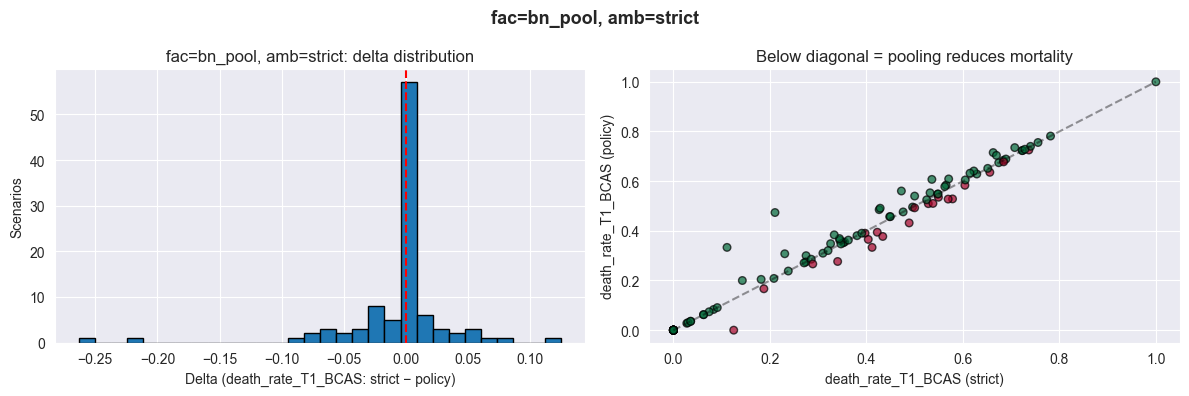

  Auto-selected box 18  (coverage=1.00, density=0.61)


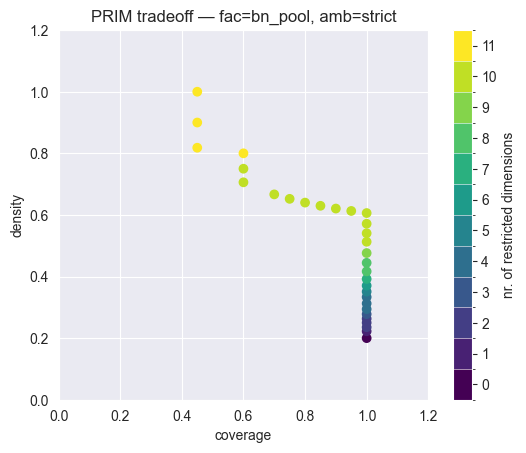

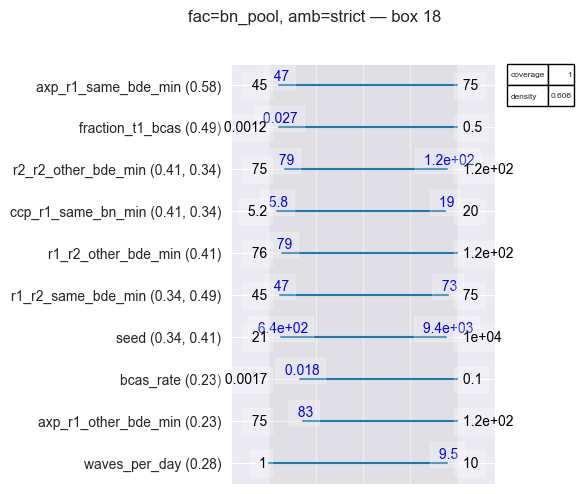

    axp_r1_other_bde_min            [83.37, 119.81]  (full: [75.20, 119.81])
    axp_r1_same_bde_min             [46.85, 74.62]  (full: [45.20, 74.62])
    bcas_rate                       [0.02, 0.10]  (full: [0.00, 0.10])
    ccp_r1_same_bn_min              [5.80, 19.00]  (full: [5.16, 19.96])
    fraction_t1_bcas                [0.03, 0.50]  (full: [0.00, 0.50])
    r1_r2_other_bde_min             [78.87, 119.90]  (full: [75.68, 119.90])
    r1_r2_same_bde_min              [46.85, 73.33]  (full: [45.09, 74.91])
    r2_r2_other_bde_min             [78.86, 117.29]  (full: [75.02, 119.66])
    seed                            [643.50, 9374.00]  (full: [21.00, 9963.00])
    waves_per_day                   [1.00, 9.50]  (full: [1.00, 10.00])


  fac=bn_pool, amb=bn_pool  —  pooling reduces T1 mortality in 46/100 scenarios (46.0%)
  mean delta (strict − policy): 0.0021


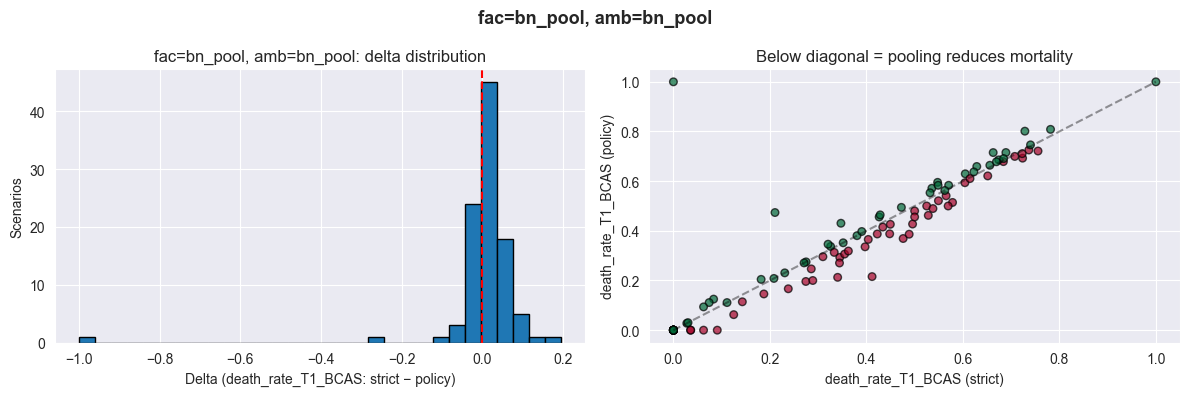

  Auto-selected box 19  (coverage=0.72, density=0.92)


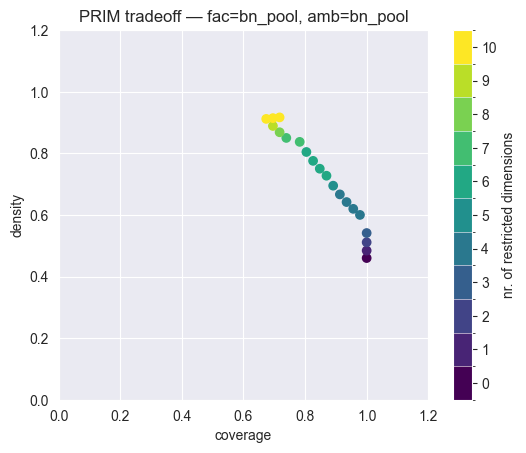

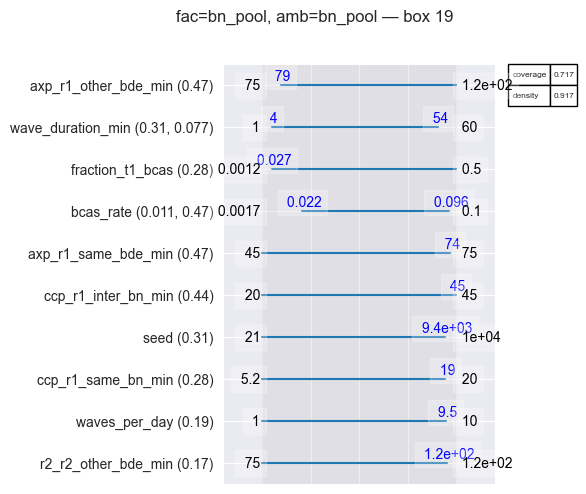

    axp_r1_other_bde_min            [79.48, 119.81]  (full: [75.20, 119.81])
    axp_r1_same_bde_min             [45.20, 73.70]  (full: [45.20, 74.62])
    bcas_rate                       [0.02, 0.10]  (full: [0.00, 0.10])
    ccp_r1_inter_bn_min             [20.46, 44.79]  (full: [20.46, 44.83])
    ccp_r1_same_bn_min              [5.16, 19.12]  (full: [5.16, 19.96])
    fraction_t1_bcas                [0.03, 0.50]  (full: [0.00, 0.50])
    r2_r2_other_bde_min             [75.02, 117.63]  (full: [75.02, 119.66])
    seed                            [21.00, 9374.00]  (full: [21.00, 9963.00])
    wave_duration_min               [4.00, 54.50]  (full: [1.00, 60.00])
    waves_per_day                   [1.00, 9.50]  (full: [1.00, 10.00])


  fac=bn_pool, amb=bde_pool  —  pooling reduces T1 mortality in 21/100 scenarios (21.0%)
  mean delta (strict − policy): -0.0598


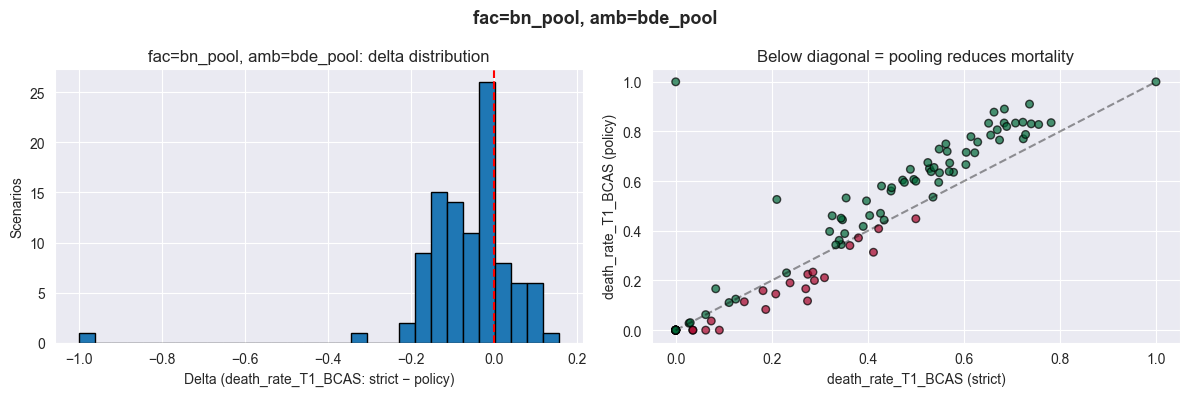

  Auto-selected box 25  (coverage=0.67, density=0.88)


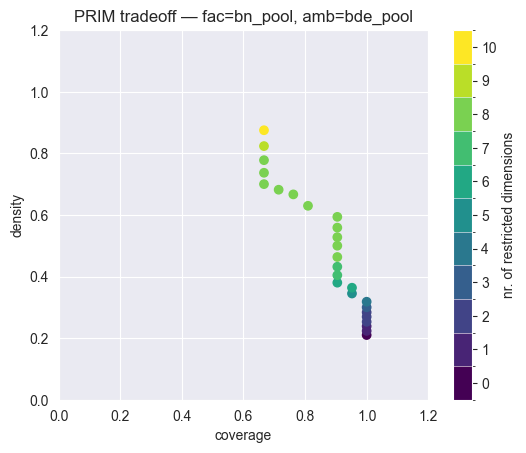

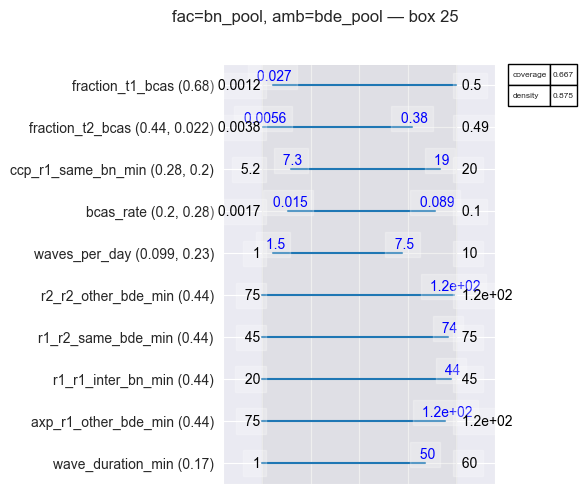

    axp_r1_other_bde_min            [75.20, 117.28]  (full: [75.20, 119.81])
    bcas_rate                       [0.01, 0.09]  (full: [0.00, 0.10])
    ccp_r1_same_bn_min              [7.33, 18.70]  (full: [5.16, 19.96])
    fraction_t1_bcas                [0.03, 0.50]  (full: [0.00, 0.50])
    fraction_t2_bcas                [0.01, 0.38]  (full: [0.00, 0.49])
    r1_r1_inter_bn_min              [20.22, 44.21]  (full: [20.22, 44.94])
    r1_r2_same_bde_min              [45.09, 73.62]  (full: [45.09, 74.91])
    r2_r2_other_bde_min             [75.02, 119.04]  (full: [75.02, 119.66])
    wave_duration_min               [1.00, 50.50]  (full: [1.00, 60.00])
    waves_per_day                   [1.50, 7.50]  (full: [1.00, 10.00])


  fac=bde_pool, amb=strict  —  pooling reduces T1 mortality in 5/100 scenarios (5.0%)
  mean delta (strict − policy): -0.0256


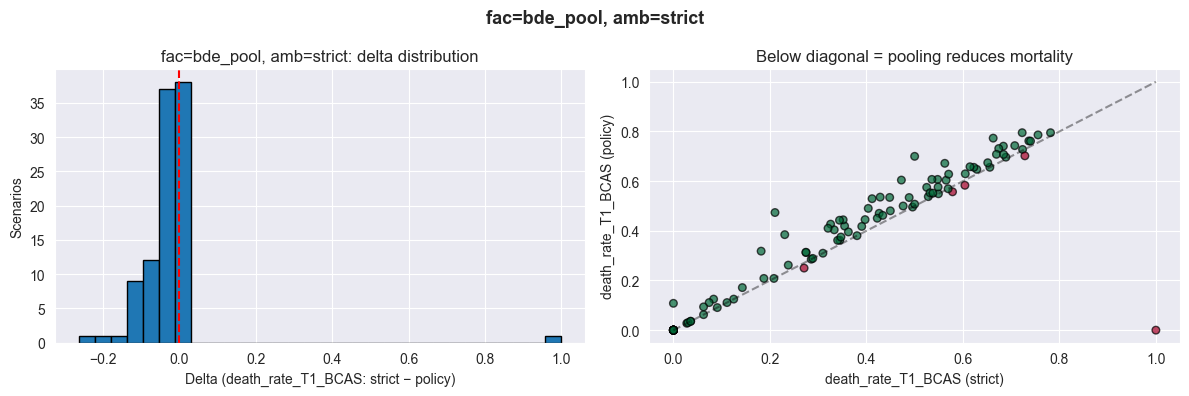

  Auto-selected box 38  (coverage=1.00, density=0.83)


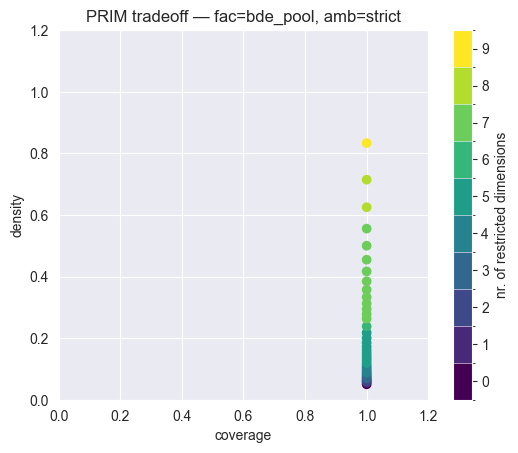

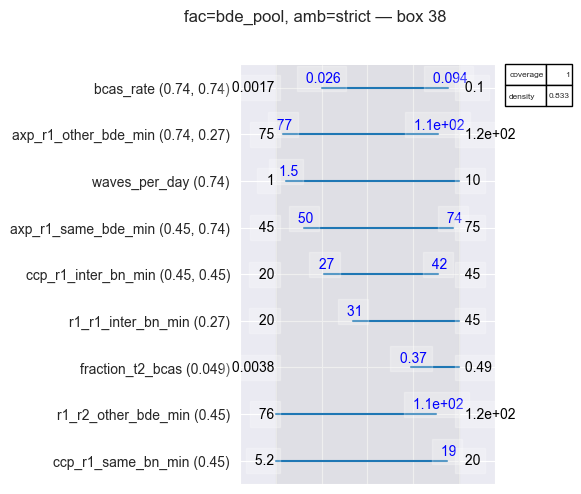

    axp_r1_other_bde_min            [76.81, 114.65]  (full: [75.20, 119.81])
    axp_r1_same_bde_min             [49.68, 73.69]  (full: [45.20, 74.62])
    bcas_rate                       [0.03, 0.09]  (full: [0.00, 0.10])
    ccp_r1_inter_bn_min             [26.90, 42.03]  (full: [20.46, 44.83])
    ccp_r1_same_bn_min              [5.16, 19.00]  (full: [5.16, 19.96])
    fraction_t2_bcas                [0.37, 0.49]  (full: [0.00, 0.49])
    r1_r1_inter_bn_min              [30.65, 44.94]  (full: [20.22, 44.94])
    r1_r2_other_bde_min             [75.68, 114.48]  (full: [75.68, 119.90])
    waves_per_day                   [1.50, 10.00]  (full: [1.00, 10.00])


  fac=bde_pool, amb=bn_pool  —  pooling reduces T1 mortality in 22/100 scenarios (22.0%)
  mean delta (strict − policy): -0.0246


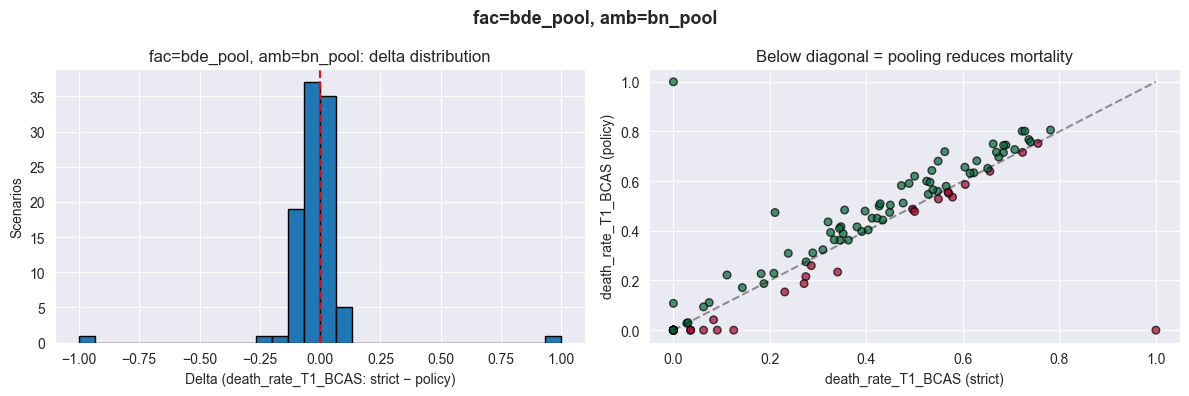

  Auto-selected box 21  (coverage=0.73, density=0.64)


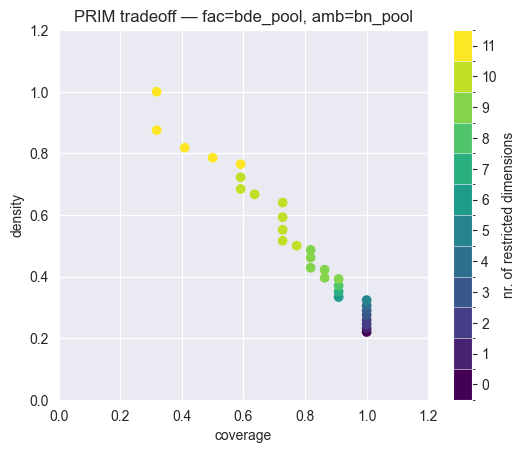

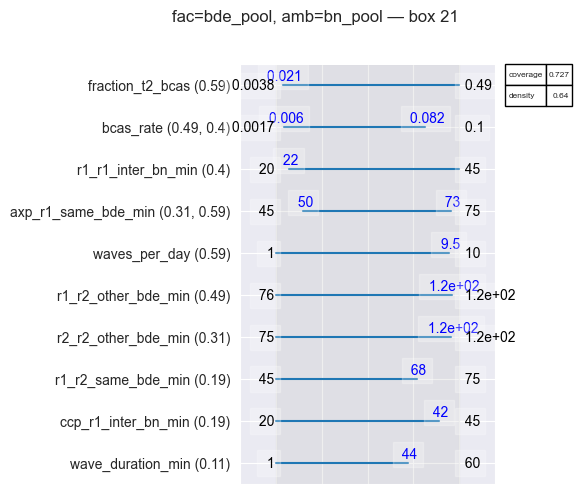

    axp_r1_same_bde_min             [49.52, 73.36]  (full: [45.20, 74.62])
    bcas_rate                       [0.01, 0.08]  (full: [0.00, 0.10])
    ccp_r1_inter_bn_min             [20.46, 42.20]  (full: [20.46, 44.83])
    fraction_t2_bcas                [0.02, 0.49]  (full: [0.00, 0.49])
    r1_r1_inter_bn_min              [21.86, 44.94]  (full: [20.22, 44.94])
    r1_r2_other_bde_min             [75.68, 118.31]  (full: [75.68, 119.90])
    r1_r2_same_bde_min              [45.09, 68.06]  (full: [45.09, 74.91])
    r2_r2_other_bde_min             [75.02, 117.76]  (full: [75.02, 119.66])
    wave_duration_min               [1.00, 43.50]  (full: [1.00, 60.00])
    waves_per_day                   [1.00, 9.50]  (full: [1.00, 10.00])


  fac=bde_pool, amb=bde_pool  —  pooling reduces T1 mortality in 22/100 scenarios (22.0%)
  mean delta (strict − policy): -0.0583


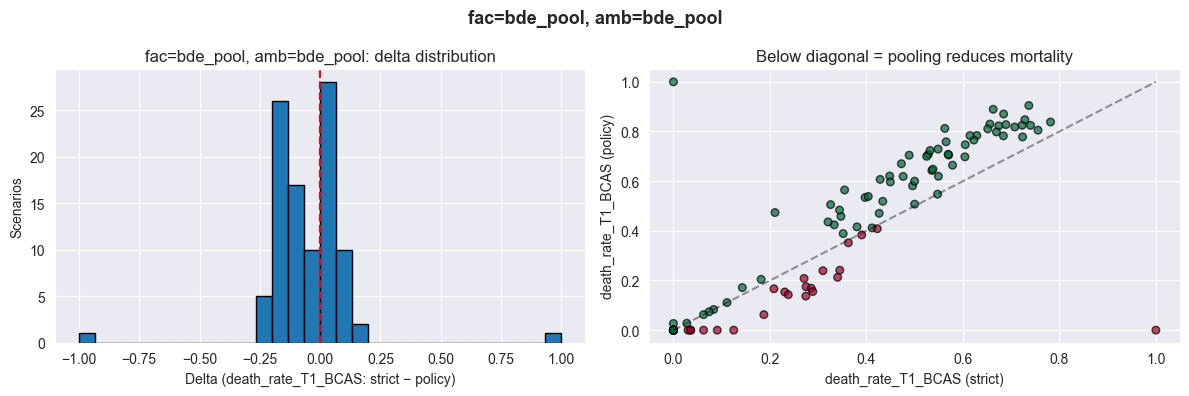

  Auto-selected box 25  (coverage=0.55, density=0.92)


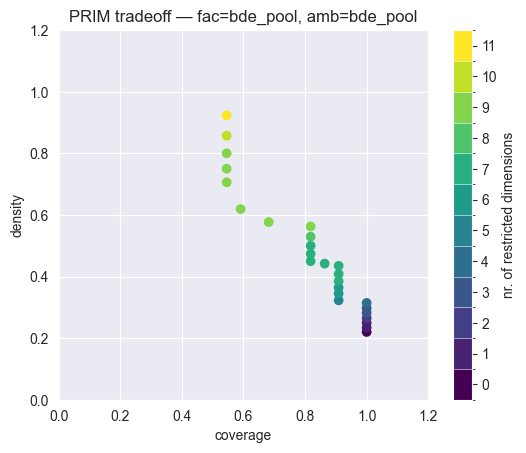

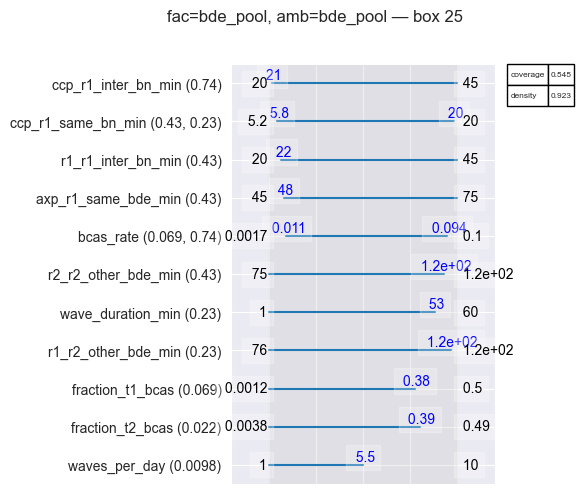

    axp_r1_same_bde_min             [47.54, 74.62]  (full: [45.20, 74.62])
    bcas_rate                       [0.01, 0.09]  (full: [0.00, 0.10])
    ccp_r1_inter_bn_min             [20.83, 44.83]  (full: [20.46, 44.83])
    ccp_r1_same_bn_min              [5.80, 19.68]  (full: [5.16, 19.96])
    fraction_t1_bcas                [0.00, 0.38]  (full: [0.00, 0.50])
    fraction_t2_bcas                [0.00, 0.39]  (full: [0.00, 0.49])
    r1_r1_inter_bn_min              [21.86, 44.94]  (full: [20.22, 44.94])
    r1_r2_other_bde_min             [75.68, 118.31]  (full: [75.68, 119.90])
    r2_r2_other_bde_min             [75.02, 116.43]  (full: [75.02, 119.66])
    wave_duration_min               [1.00, 53.00]  (full: [1.00, 60.00])
    waves_per_day                   [1.00, 5.50]  (full: [1.00, 10.00])


In [5]:
results_summary = []

for fe, ae in POLICIES:
    label = f"fac={POLICY_LABELS[fe]}, amb={POLICY_LABELS[ae]}"
    mask = (df["facility_eligibility"] == fe) & (df["ambulance_eligibility"] == ae)
    policy_outcome = (
        df.loc[mask]
        .groupby("scenario")[OUTCOME]
        .mean()
        .rename("policy")
    )

    comp = pd.concat([baseline_outcome, policy_outcome], axis=1).dropna()
    comp["delta"] = comp["strict"] - comp["policy"]
    comp["pooling_reduces_mortality"] = (comp["delta"] > 0).astype(int)

    n_better = comp["pooling_reduces_mortality"].sum()
    n_total  = len(comp)
    results_summary.append({
        "policy": label,
        "n_better": n_better,
        "n_total": n_total,
        "pct": 100 * n_better / n_total,
        "mean_delta": comp["delta"].mean(),
    })

    print(f"\n{'='*70}")
    print(f"  {label}  —  pooling reduces T1 mortality in "
          f"{n_better}/{n_total} scenarios ({100*n_better/n_total:.1f}%)")
    print(f"  mean delta (strict − policy): {comp['delta'].mean():.4f}")
    print(f"={'='*70}")

    # --- Histograms ---
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].hist(comp["delta"], bins=30, edgecolor="black")
    axes[0].axvline(0, color="red", ls="--")
    axes[0].set_xlabel(f"Delta ({OUTCOME}: strict − policy)")
    axes[0].set_ylabel("Scenarios")
    axes[0].set_title(f"{label}: delta distribution")

    axes[1].scatter(comp["strict"], comp["policy"],
                    c=comp["pooling_reduces_mortality"], cmap="RdYlGn_r",
                    edgecolors="black", alpha=0.7, s=30)
    lims = [min(comp[["strict","policy"]].min()),
            max(comp[["strict","policy"]].max())]
    axes[1].plot(lims, lims, "k--", alpha=0.4)
    axes[1].set_xlabel(f"{OUTCOME} (strict)")
    axes[1].set_ylabel(f"{OUTCOME} (policy)")
    axes[1].set_title(f"Below diagonal = pooling reduces mortality")
    plt.suptitle(label, fontsize=13, fontweight="bold")
    plt.tight_layout()
    plt.show()

    # --- PRIM ---
    if n_better < 3 or n_better > n_total - 3:
        print(f"  Too few cases ({n_better}) or too uniform — skipping PRIM.\n")
        continue

    x_prim = x_all.loc[comp.index].reset_index(drop=True)
    y_prim = comp["pooling_reduces_mortality"].values

    p = prim.Prim(x_prim, y_prim, threshold=0.5, threshold_type=prim.ABOVE)
    box = p.find_box()

    traj = box.peeling_trajectory
    score = traj["coverage"] * traj["density"]
    bi = int(score.idxmax())
    print(f"  Auto-selected box {bi}  "
          f"(coverage={traj.loc[bi, 'coverage']:.2f}, "
          f"density={traj.loc[bi, 'density']:.2f})")

    box.show_tradeoff()
    plt.title(f"PRIM tradeoff — {label}")
    plt.show()

    box.inspect(bi, style="graph")
    plt.suptitle(f"{label} — box {bi}", y=1.02)
    plt.tight_layout()
    plt.show()

    box.select(bi)
    lim = box.box_lim
    any_restricted = False
    for col in uncertainty_cols:
        lo, hi = lim[col].iloc[0], lim[col].iloc[1]
        full_lo, full_hi = x_prim[col].min(), x_prim[col].max()
        if lo > full_lo + 1e-9 or hi < full_hi - 1e-9:
            print(f"    {col:30s}  [{lo:.2f}, {hi:.2f}]  "
                  f"(full: [{full_lo:.2f}, {full_hi:.2f}])")
            any_restricted = True
    if not any_restricted:
        print("    No dimensions restricted.")
    print()

In [6]:
summary_df = pd.DataFrame(results_summary)
print("\nSummary: fraction of scenarios where pooling reduces T1 mortality\n")
display(summary_df.style.format({"pct": "{:.1f}%", "mean_delta": "{:.4f}"}))


Summary: fraction of scenarios where pooling reduces T1 mortality


,policy,n_better,n_total,pct,mean_delta
0,"fac=strict, amb=bn_pool",51,100,51.0%,0.0077
1,"fac=strict, amb=bde_pool",26,100,26.0%,-0.0573
2,"fac=bn_pool, amb=strict",20,100,20.0%,-0.0065
3,"fac=bn_pool, amb=bn_pool",46,100,46.0%,0.0021
4,"fac=bn_pool, amb=bde_pool",21,100,21.0%,-0.0598
5,"fac=bde_pool, amb=strict",5,100,5.0%,-0.0256
6,"fac=bde_pool, amb=bn_pool",22,100,22.0%,-0.0246
7,"fac=bde_pool, amb=bde_pool",22,100,22.0%,-0.0583
